# Ejercicio 3 — Descenso de gradiente con cuatro variables
## 1. Función, gradiente y algoritmo
$$f(x)=x_1^4+2x_2^4+3x_3^4+4x_4^4-4x_1-8x_2-12x_3-16x_4+(x_1-x_2)^2+(x_2-x_3)^2+(x_3-x_4)^2.$$
Las derivadas parciales son:
$$\nabla f(x)=\begin{pmatrix}4x_1^3-4+2(x_1-x_2)\\8x_2^3-8+2(x_2-x_1)+2(x_2-x_3)\\12x_3^3-12+2(x_3-x_2)+2(x_3-x_4)\\16x_4^3-16+2(x_4-x_3)\end{pmatrix}.$$
Se aplica $x^{(i+1)}=x^{(i)}-\gamma\nabla f(x^{(i)})$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

def f(x):
    a,b,c,d = x
    return a**4+2*b**4+3*c**4+4*d**4-4*a-8*b-12*c-16*d+(a-b)**2+(b-c)**2+(c-d)**2

def gradiente(x):
    a,b,c,d = x
    return np.array([4*a**3-4+2*(a-b),8*b**3-8+2*(b-a)+2*(b-c),12*c**3-12+2*(c-b)+2*(c-d),16*d**3-16+2*(d-c)])

# Comprobación simbólica
v = sp.symbols('x1:5')
assert all(sp.simplify(a-b)==0 for a,b in zip([sp.diff(f(v), t) for t in v], gradiente(v)))
print('Gradiente verificado:', gradiente(v))

def descenso(x0, gamma, tol=1e-6, max_iter=10000):
    x = np.array(x0, dtype=float)
    historial = [f(x)]
    trayectoria = [x.copy()]
    for i in range(max_iter+1):
        g = gradiente(x)
        if np.linalg.norm(g) < tol:
            return x, i, historial, trayectoria, 'Converge'
        if i == max_iter:
            return x, i, historial, trayectoria, 'Límite de iteraciones'
        nuevo = x-gamma*g
        # Interrumpir crecimiento explosivo antes de desbordamiento numérico
        if not np.all(np.isfinite(nuevo)) or np.linalg.norm(nuevo)>1e6:
            return x, i, historial, trayectoria, 'Diverge (umbral de seguridad)'
        x = nuevo
        historial.append(f(x))
        trayectoria.append(x.copy())

Gradiente verificado: [4*x1**3 + 2*x1 - 2*x2 - 4 -2*x1 + 8*x2**3 + 4*x2 - 2*x3 - 8
 -2*x2 + 12*x3**3 + 4*x3 - 2*x4 - 12 -2*x3 + 16*x4**3 + 2*x4 - 16]


## 2. Selección heurística de $\gamma$ y $x^{(0)}$
Se prueban tasas pequeñas, intermedias y grandes desde distintos puntos no óptimos. Se limita cada prueba a 10 000 actualizaciones para evitar ejecuciones indefinidas; la convergencia solo se declara si la norma del gradiente es menor que $10^{-6}$. El umbral de seguridad evita desbordamientos en pruebas divergentes.

In [2]:
pruebas = [(0.001,[0,0,0,0]),(0.01,[0,0,0,0]),(0.03,[0,0,0,0]),(0.04,[0,0,0,0]),(0.05,[0,0,0,0]),(0.1,[0,0,0,0]),(0.03,[-1,-1,-1,-1]),(0.03,[2,2,2,2])]
filas = []
for gamma,x0 in pruebas:
    x,i,h,t,estado = descenso(x0,gamma)
    cambios = np.diff(np.array(t)[:,3])
    alternancias = int(np.sum(cambios[1:]*cambios[:-1]<0))
    filas.append({'gamma':gamma,'x0':str(x0),'Estado':estado,'Iteraciones':i,'f final':h[-1],'Norma gradiente':np.linalg.norm(gradiente(x)),'Alternancias x4':alternancias})
tabla = pd.DataFrame(filas)
display(tabla)

,gamma,x0,Estado,Iteraciones,f final,Norma gradiente,Alternancias x4
0,0.001,"[0, 0, 0, 0]",Converge,1299,-3.000000e+01,9.869416e-07,0
1,0.010,"[0, 0, 0, 0]",Converge,123,-3.000000e+01,9.540614e-07,0
2,0.030,"[0, 0, 0, 0]",Converge,36,-3.000000e+01,6.554767e-07,32
3,0.040,"[0, 0, 0, 0]",Límite de iteraciones,10000,-2.987301e+01,3.724897e+00,9998
4,0.050,"[0, 0, 0, 0]",Límite de iteraciones,10000,-2.603272e+01,2.129169e+01,9998
5,0.100,"[0, 0, 0, 0]",Diverge (umbral de seguridad),4,1.166766e+23,1.129309e+18,3
6,0.030,"[-1, -1, -1, -1]",Converge,41,-3.000000e+01,6.333777e-07,18
7,0.030,"[2, 2, 2, 2]",Converge,30,-3.000000e+01,6.218872e-07,27


Se elige una tasa intermedia que converge rápidamente desde el origen, un punto inicial sencillo y no óptimo. Las alternancias de dirección en la cuarta coordenada permiten detectar oscilaciones, incluso cuando estas se amortiguan y el algoritmo converge. Las tasas demasiado grandes pueden provocar oscilaciones persistentes o divergencia.

In [3]:
gamma = 0.03
x0 = [0,0,0,0]
x,i,h,t,estado = descenso(x0,gamma)
assert estado == 'Converge'
print(tabla.to_string(index=False))

 gamma               x0                        Estado  Iteraciones       f final  Norma gradiente  Alternancias x4
 0.001     [0, 0, 0, 0]                      Converge         1299 -3.000000e+01     9.869416e-07                0
 0.010     [0, 0, 0, 0]                      Converge          123 -3.000000e+01     9.540614e-07                0
 0.030     [0, 0, 0, 0]                      Converge           36 -3.000000e+01     6.554767e-07               32
 0.040     [0, 0, 0, 0]         Límite de iteraciones        10000 -2.987301e+01     3.724897e+00             9998
 0.050     [0, 0, 0, 0]         Límite de iteraciones        10000 -2.603272e+01     2.129169e+01             9998
 0.100     [0, 0, 0, 0] Diverge (umbral de seguridad)            4  1.166766e+23     1.129309e+18                3
 0.030 [-1, -1, -1, -1]                      Converge           41 -3.000000e+01     6.333777e-07               18
 0.030     [2, 2, 2, 2]                      Converge           30 -3.000000e+01

## 3. Resultado final
Se utiliza la norma euclidiana del gradiente como criterio de parada. Como verificación independiente, cada término $k(x_j^4-4x_j)$ alcanza su mínimo único en $x_j=1$ y las diferencias al cuadrado son no negativas y se anulan cuando todas las coordenadas son iguales. Por ello el mínimo global exacto es $(1,1,1,1)$, con valor $-30$. Este punto no se utiliza para inicializar el algoritmo.

In [4]:
np.set_printoptions(precision=12)
print('Tasa:', gamma)
print('Punto inicial:', x0)
print('Estado:', estado)
print('Mínimo encontrado:', x)
print('f(x*):', f(x))
print('Gradiente final:', gradiente(x))
print('Norma del gradiente:', np.linalg.norm(gradiente(x)))
print('Iteraciones:', i)
assert np.linalg.norm(gradiente(x)) < 1e-6

Tasa: 0.03
Punto inicial: [0, 0, 0, 0]
Estado: Converge
Mínimo encontrado: [0.999999952688 0.999999993303 0.999999999489 0.999999999966]
f(x*): -29.999999999999986
Gradiente final: [-6.489702599755e-07 -9.186097238434e-08 -6.957999287849e-09
 -6.991329737360e-10]
Norma del gradiente: 6.554767266051577e-07
Iteraciones: 36


## 4. Gráfica de la función contra la iteración

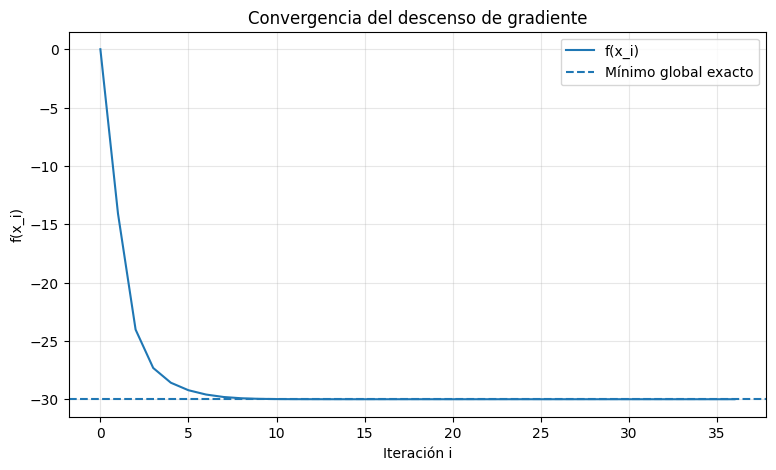

In [5]:
plt.figure(figsize=(9,5))
plt.plot(range(len(h)),h, label='f(x_i)')
plt.axhline(-30, linestyle='--',label='Mínimo global exacto')
plt.xlabel('Iteración i')
plt.ylabel('f(x_i)')
plt.title('Convergencia del descenso de gradiente')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

La gráfica muestra la evolución del valor de la función desde el origen hasta el mínimo. La tolerancia se verifica con el gradiente, no únicamente con el cambio de la función.